# 09. 최종 2단계 사양 — Stellantis N.V.와 KAMP에 같은 모델
- **1단계 (오늘 몇 개를 검사할까):** 집계 로지스틱으로 날짜별 불량 수를 추정한다. 예산 = 추정 불량 수 × m (m = 2.5·5·10) 또는 비율 b%.
- **2단계 (무엇을 검사할까):** PVC MLP 위험 점수(10시드 평균, 반복 5에서 안정성 확인) 상위부터 예산만큼 추천한다.
- 공통: 입력은 타점당 전류·전압·통전시간·가압력과 파생 3개. 학습 정답은 날짜별 불량 개수만. 날짜 하나를 빼고 학습해 평가한다. 06·08 캐시를 쓴다.

이 조합(개수용 집계 로지스틱)은 06 결과를 본 뒤 고른 것이라 탐색 결과로 표시한다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from scipy.stats import binomtest
import br
from br import spec as S, budget as B, plot as P
from wl.metrics import inclusion_prob
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
DATA = {"polito": S.load_polito(), "kamp": S.load_kamp()}
sc = pd.read_pickle(br.RES / "same_model_scores.pkl")
RANK_M, COUNT_M = "PVC MLP", "집계 로지스틱"

def per_seed(ds, model, col):
    g = sc[(sc.data == ds) & (sc.model == model)]
    return [gg.sort_values("row")[col].values for _, gg in g.groupby("seed")]

def day_err(ds, model):
    X, day, cnt, y, blk = DATA[ds]
    ps = per_seed(ds, model, "prob"); ok = ~np.isnan(ps[0])
    pred = np.mean([pd.Series(p[ok]).groupby(day[ok]).sum() for p in ps], 0)
    idx = np.unique(day[ok])
    return pd.Series(pred, idx), cnt.loc[idx]

## 1. 개수 추정 개선이 우연인가 — 날짜별 오차 비교
날짜 단위 대응 비교. 부호검정(2단계 오차가 더 작은 날의 수)과 날짜 복원추출 구간.

In [2]:
rng = np.random.default_rng(0)
rows = []
for ds in DATA:
    p2, act = day_err(ds, COUNT_M); p0, _ = day_err(ds, "고정 불량률")
    e2, e0 = (p2 - act).abs(), (p0 - act).abs()
    d_ = (e2 - e0).values
    boot = np.array([d_[rng.integers(0, len(d_), len(d_))].mean() for _ in range(10000)])
    win = int((d_ < 0).sum()); n_ = int((d_ != 0).sum())
    rows.append(dict(데이터=ds, 날짜수=len(d_), 고정불량률_MAE=e0.mean(), 단계1_MAE=e2.mean(), 차이=d_.mean(),
                     차이_95구간=f"[{np.quantile(boot,.025):+.2f}, {np.quantile(boot,.975):+.2f}]",
                     개선된날=f"{win}/{n_}", 부호검정p=binomtest(win, n_, .5, alternative="greater").pvalue))
    if ds == "kamp":
        kd = pd.DataFrame({"실제": act, "고정 불량률": p0.round(2), "1단계 추정": p2.round(2)});
sig = pd.DataFrame(rows).round(3); sig.to_csv(br.RES / "final_count_significance.csv", index=False, encoding="utf-8-sig")
display(sig); kd

,데이터,날짜수,고정불량률_MAE,단계1_MAE,차이,차이_95구간,개선된날,부호검정p
0,polito,20,2.467,2.719,0.252,"[-0.53, +1.12]",13/20,0.132
1,kamp,8,2.190,1.691,-0.498,"[-1.31, +0.09]",4/8,0.637


,실제,고정 불량률,1단계 추정
2020-03-24,4.0,4.62,3.37
2020-03-25,8.0,4.69,5.18
2020-03-26,7.0,3.44,3.98
2020-03-30,4.0,5.83,6.11
2020-03-31,5.0,7.21,6.52
2020-04-02,4.0,8.44,5.41
2020-04-03,4.0,2.95,5.06
2020-04-07,3.0,2.50,3.96


## 2. Stellantis N.V. — 최종 사양의 검사 예산 성능 (숨긴 정답으로 채점)

In [3]:
X, pday, pcnt, py, _ = DATA["polito"]
body = wldata.load_polito().body.values
ub = np.unique(body); Wb = np.stack([np.bincount(d_, minlength=len(ub)) for d_ in rng.integers(0, len(ub), (5000, len(ub)))])[:, np.searchsorted(ub, body)]
ud, gi = np.unique(pday, return_inverse=True); n = np.bincount(gi); pos = np.bincount(gi, weights=py)
RS = per_seed("polito", RANK_M, "score"); CS = per_seed("polito", COUNT_M, "prob")
RMEAN = np.mean(RS, 0)   # KAMP 배포와 같은 방식: 시드 평균 점수로 한 번 순위를 매긴다
def evaluate(k):
    ps = inclusion_prob(RMEAN, k.astype(float), gi)
    pr = (k / n)[gi]
    d_ = (Wb @ (ps * py)) / (Wb @ py) - (Wb @ (pr * py)) / (Wb @ py)
    return k.sum(), (ps * py).sum(), (pr * py).sum(), d_
rows = []
for nm, k in ([(f"비율 {int(b*100)}%", np.ceil(b * n - 1e-9)) for b in (.05, .1, .2, .3)] +
              [(f"추정 개수 × {m}", np.minimum(np.ceil(m * np.mean([np.bincount(gi, weights=c) for c in CS], 0) - 1e-9), n)) for m in (2.5, 5, 10)]):
    kk, h, h0, d_ = evaluate(k)
    rows.append({"예산": nm, "검사수": int(kk), "검사비율": kk / len(py), "포착": h, "미포착": py.sum() - h, "포착률": h / py.sum(),
                 "같은 수 무작위": h0, "무작위 대비 포착률 차이 [95%]": f"{d_.mean():+.3f} [{np.quantile(d_,.025):+.3f}, {np.quantile(d_,.975):+.3f}]"})
pt = pd.DataFrame(rows).round(3); pt.to_csv(br.RES / "final_polito_budget.csv", index=False, encoding="utf-8-sig"); pt

,예산,검사수,검사비율,포착,미포착,포착률,같은 수 무작위,무작위 대비 포착률 차이 [95%]
0,비율 5%,109,0.055,8.0,71.0,0.101,4.917,"+0.037 [-0.021, +0.093]"
1,비율 10%,206,0.104,22.0,57.0,0.278,8.571,"+0.163 [+0.049, +0.254]"
2,비율 20%,403,0.204,37.0,42.0,0.468,15.992,"+0.258 [+0.118, +0.370]"
3,비율 30%,601,0.304,52.0,27.0,0.658,24.400,"+0.343 [+0.196, +0.454]"
4,추정 개수 × 2.5,230,0.116,26.0,53.0,0.329,9.586,"+0.201 [+0.076, +0.305]"
5,추정 개수 × 5,446,0.226,36.0,43.0,0.456,18.852,"+0.210 [+0.078, +0.317]"
6,추정 개수 × 10,848,0.429,61.0,18.0,0.772,36.308,"+0.306 [+0.174, +0.412]"


## 3. KAMP — 최종 추천 목록
3/27(정답 없음)은 정답 있는 8일 전체로 학습해 점수와 개수를 낸다. 복사 블록은 순위에서 빼고 `품질확인`으로 표시한다.
추정 불량 수는 블록을 포함한 그날 전체 타점의 확률 합이다(일별 정답이 그날 전체에 대한 값이므로).

In [4]:
X, kday, kcnt, _, kblk = DATA["kamp"]
lab_days = [d for d in kcnt.index if not np.isnan(kcnt[d])]
def full_fill(model, col):
    vals = np.mean(per_seed("kamp", model, col), 0)
    miss = np.isnan(vals)
    if miss.any():
        lab = np.isin(kday, lab_days); u, bag = np.unique(kday[lab], return_inverse=True)
        out = [S.fit_score(model, X, bag, kcnt.loc[u].values.astype(int), lab, miss, s) for s in sorted(sc[(sc.data == "kamp") & (sc.model == model)].seed.unique())]
        vals[miss] = np.mean([o[0 if col == "score" else 1] for o in out], 0)
    return vals
score, cprob = full_fill(RANK_M, "score"), full_fill(COUNT_M, "prob")
K = pd.DataFrame({"date": kday, "row": np.arange(len(kday)), "블록": kblk, "위험점수": score, "개수모델확률": cprob})
K["상태"] = np.where(K.블록, "품질확인(복사 블록)", "순위 부여")
K.loc[~K.블록, "일내순위"] = K[~K.블록].groupby("date").위험점수.rank(ascending=False, method="first")
K["순위대상수"] = K.date.map(K[~K.블록].groupby("date").size())
est = K.groupby("date").개수모델확률.sum()
K["추정불량수"] = K.date.map(est)
for b in (.05, .1, .2):
    K[f"추천_{int(b*100)}%"] = K.일내순위 <= np.ceil(b * K.순위대상수)
for m in (2.5, 5, 10):
    K[f"추천_{m}배"] = K.일내순위 <= np.ceil(m * K.추정불량수)
raw = pd.read_excel(wldata.KAMP_XLSX, sheet_name="Raw data")
K = pd.concat([K, raw[["idx", "weld current(kA)", "weld Voltage(v)", "weld time(ms)", "weld force(bar)"]].reset_index(drop=True)], axis=1)
K.to_csv(br.RES / "final_kamp_recommendations.csv", index=False, encoding="utf-8-sig")
ks = K.groupby("date").agg(타점수=("row", "size"), 블록=("블록", "sum"), 추정불량수=("추정불량수", "first"),
                           **{c: (c, "sum") for c in K.columns if c.startswith("추천_")})
ks["실제불량"] = kcnt.reindex(ks.index).values
ks.round(1)

,타점수,블록,추정불량수,추천_5%,추천_10%,추천_20%,추천_2.5배,추천_5배,추천_10배,실제불량
date,,,,,,,,,,
2020-03-24,1200,0,3.4,60,120,240,9,17,34,4.0
2020-03-25,1352,291,5.2,54,107,213,13,26,52,8.0
2020-03-26,1000,0,4.0,50,100,200,10,20,40,7.0
2020-03-27,1648,291,5.7,68,136,272,15,29,58,NaN
2020-03-30,1470,0,6.1,74,147,294,16,31,62,4.0
2020-03-31,1800,291,6.5,76,151,302,17,33,66,5.0
2020-04-02,2000,0,5.4,100,200,400,14,28,55,4.0
2020-04-03,800,291,5.1,26,51,102,13,26,51,4.0
2020-04-07,669,0,4.0,34,67,134,10,20,40,3.0


## 4. 보고서용 요약 그림

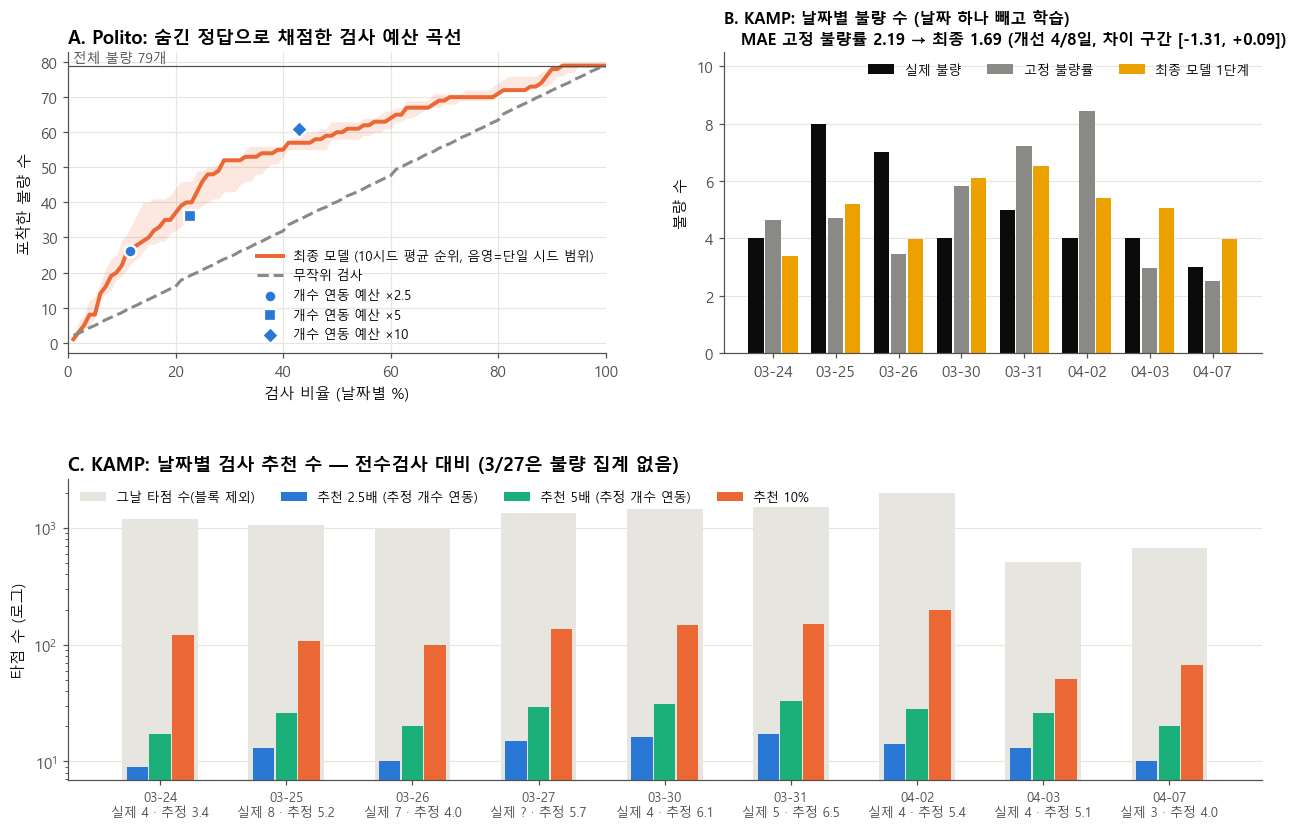

In [5]:
fig = plt.figure(figsize=(14, 8.6)); gs = fig.add_gridspec(2, 2, height_ratios=[1, 1], hspace=.42, wspace=.22)
ax1 = fig.add_subplot(gs[0, 0]); ax2 = fig.add_subplot(gs[0, 1]); ax3 = fig.add_subplot(gs[1, :])
# (A) Stellantis N.V. 예산 곡선
bud = B.BUDGETS
cur = np.array([[ (inclusion_prob(s, np.ceil(b * n - 1e-9), gi) * py).sum() for b in bud] for s in RS])
rnd = np.array([(np.ceil(b * n - 1e-9) / n * pos).sum() for b in bud])
ax1.fill_between(bud * 100, cur.min(0), cur.max(0), color=P.PAL[1], alpha=.15, lw=0)
ax1.plot(bud * 100, [(inclusion_prob(RMEAN, np.ceil(b * n - 1e-9), gi) * py).sum() for b in bud], color=P.PAL[1], lw=2.6,
         label="최종 모델 (10시드 평균 순위, 음영=단일 시드 범위)")
ax1.plot(bud * 100, rnd, "--", color=P.GRAY, label="무작위 검사")
for m, mk in zip((2.5, 5, 10), ("o", "s", "D")):
    r = pt[pt.예산 == f"추정 개수 × {m}"].iloc[0]
    ax1.scatter(r.검사비율 * 100, r.포착, s=60, marker=mk, color=P.PAL[0], edgecolor="white", linewidth=1.5, zorder=4, label=f"개수 연동 예산 ×{m}")
ax1.axhline(py.sum(), color=P.INK2, lw=.8); ax1.text(1, py.sum() + 1, f"전체 불량 {int(py.sum())}개", color=P.INK2, fontsize=9)
ax1.set_xlim(0, 100); ax1.set_xlabel("검사 비율 (날짜별 %)"); ax1.set_ylabel("포착한 불량 수")
ax1.set_title("A. Stellantis N.V.: 숨긴 정답으로 채점한 검사 예산 곡선", loc="left", fontweight="bold"); ax1.legend(fontsize=8.5, loc="lower right")
# (B) KAMP 개수
x = np.arange(len(lab_days)); w = .27
ax2.bar(x - w, kcnt.loc[lab_days].values, w * .9, color=P.INK, label="실제 불량")
ax2.bar(x, kd.loc[lab_days, "고정 불량률"].values, w * .9, color=P.GRAY, label="고정 불량률")
ax2.bar(x + w, kd.loc[lab_days, "1단계 추정"].values, w * .9, color=P.PAL[3], label="최종 모델 1단계")
ax2.set_xticks(x); ax2.set_xticklabels([d[5:] for d in lab_days]); ax2.grid(axis="x", visible=False)
r = sig[sig.데이터 == "kamp"].iloc[0]
ax2.set_title(f"B. KAMP: 날짜별 불량 수 (날짜 하나 빼고 학습)\n   MAE 고정 불량률 {r.고정불량률_MAE:.2f} → 최종 {r.단계1_MAE:.2f} (개선 {r.개선된날}일, 차이 구간 {r.차이_95구간})", loc="left", fontweight="bold", fontsize=10.5)
ax2.set_ylabel("불량 수"); ax2.legend(fontsize=8.5, ncol=3, loc="upper right"); ax2.set_ylim(0, 10.5)
# (C) KAMP 날짜별 검사 예산
dd = list(ks.index); x = np.arange(len(dd))
ax3.bar(x, ks.타점수 - ks.블록, .6, color=P.GRID, label="그날 타점 수(블록 제외)")
for i, (c, col) in enumerate([("추천_2.5배", P.PAL[0]), ("추천_5배", P.PAL[2]), ("추천_10%", P.PAL[1])]):
    ax3.bar(x + (i - 1) * .18, ks[c], .17, color=col, label=c.replace("추천_", "추천 ").replace("배", "배 (추정 개수 연동)"))
ax3.set_yscale("log"); ax3.set_xticks(x); ax3.set_xticklabels([f"{d[5:]}\n실제 {int(a) if a == a else '?'} · 추정 {e:.1f}" for d, a, e in zip(dd, ks.실제불량, ks.추정불량수)], fontsize=8.5)
ax3.set_ylabel("타점 수 (로그)"); ax3.grid(axis="x", visible=False); ax3.legend(fontsize=8.5, ncol=4, loc="upper left")
ax3.set_title("C. KAMP: 날짜별 검사 추천 수 — 전수검사 대비 (3/27은 불량 집계 없음)", loc="left", fontweight="bold")
P.save(fig, "10_final_summary"); plt.show()